In [ ]:
#Byjus Case
import pandas as pd
import numpy as np

df = pd.read_excel("/Lecture2_data.xlsx")

FileNotFoundError: [Errno 2] No such file or directory: '/Lecture2_data.xlsx'

In [ ]:
#Data Description
print(df.head)
print(df.shape)
df.info()
df["Customer_Rating"]= df["Customer_Rating"].fillna(df["Customer_Rating"].mean())

In [ ]:
#Data Type
print(df.dtypes)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
#Top 10 profit/loss product
df["Total_Cost_Lakh"]= (df["Marketing_Spend_Lakh"]+ df["Content_Cost_Lakh"]+ df["Salary_Cost_Lakh"]+ df["Other_Cost_Lakh"])
df["Profit_Lakh"]= df["Revenue_Lakh"] - df["Total_Cost_Lakh"]
print(df[["Product","Revenue_Lakh","Total_Cost_Lakh","Profit_Lakh"]].head(10))

In [ ]:
#Missing Value
print(df.isna().sum())

In [ ]:
#Decision making structures
#If Statements
rating = df["Customer_Rating"].mean()

if rating>=4:
  print("Customer satisfaction is good")

In [ ]:
#Decision Making Structures
#If Statements
Revenue = df["Revenue_Lakh"].mean()

if Revenue >400:
   print("Growth")

In [ ]:
Revenue = df["Revenue_Lakh"].mean()
print("Average Revenue:", Revenue)

if Revenue>300:
  print("Average Revenue is High")

LECTURE 3 Continued

In [ ]:
#Decision making structures
#If else
revenue =df["Revenue_Lakh"].mean()

if revenue>=300:
  print("Average revenue is high")

else:
  print("Average revenue is low")

In [ ]:
from IPython.core.inputtransformer2 import ESCAPE_DOUBLES
#Decision making structures
#Nested If Statement in Python
revenue = df["Revenue_Lakh"].mean()
rating = df["Customer_Rating"].mean()

if revenue>=300:
  print("Revenue is high")

  if rating >=4:
    print("Customer satisfaction is also good")
  else:
      print("Customer satisfaction needs improvement")
else:
      print("Revenue is low")


In [ ]:
# Find the average customer rating
rating = df["Customer_Rating"].mean()

# Make a decision based on the rating
if rating>=4.5:
    print("Excellent")

elif rating>=4.0:
  print("Good")

elif rating>=3.0:
  print("Average")

else:
  print("Needs improvement")

In [ ]:
# For Loop
for rating in df["Customer_Rating"]:

  if rating>=4:
    print("Good Rating")
  else:
    print("Needs Improvement")

In [ ]:
# FOR Loop with range() iloc= integer location

for i in range(10):
    print(df["Product"].iloc[i], df["Revenue_Lakh"].iloc[i])

In [ ]:
#WHILE Loop in Python
#WHILE loop and i,j is variable to track
i=0

while i<5:
  revenue = df["Revenue_Lakh"].iloc[i]

  if revenue>=300:
    print("High Revenue", revenue)
  else:
    print("Low Revenue", revenue)

  i=i+1

In [ ]:
# Method
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

sns.set_style("whitegrid")
file_path = '/SkyBridge_Airline_Data (1).xlsx'

raf = pd.read_excel(file_path, sheet_name="Unclean_Data")
raf.head()

In [ ]:
# Define 'raw' from the loaded DataFrame 'raf'
raw = raf.copy()

# Create a copy of the original dataset so raw remains unchanged
df = raw.copy()

# Define standard validation rules (low, high) for column validation
rules = {
    "Passengers": (1, 300),
    "Ticket_Price": (0, 50000),
    "Flight_Duration_Min": (30, 1000)
}

# Check each column using its minimum and maximum allowed values
for col, (low, high) in rules.items():
    if col in df.columns:
        # Find values below the minimum OR above the maximum
        bad_rows = (df[col] < low) | (df[col] > high)

        # Print the column name and count of impossible values found
        print(col, "-> removed", bad_rows.sum(), "impossible value(s)")

        # Replace impossible values with NaN (missing values)
        # This does not delete the entire row
        df.loc[bad_rows, col] = np.nan

# Print a blank line to improve readability
print()

# Count all missing cells in the original dataset
print("Blank cells before:", raw.isnull().sum().sum())

# Count all missing cells after replacing impossible values
print("Blank cells after :", df.isnull().sum().sum())

In [ ]:
# Select the variable
df["Ancillary_Revenue"].describe()
col = "Ancillary_Revenue"

# Start with the original, uncapped data
before = raw[col].copy()

# Create a fresh dataset for capping
df_capped = raw.copy()

# Calculate Q1, Q3 and IQR using original data
Q1 = before.quantile(0.25)
Q3 = before.quantile(0.75)
IQR = Q3 - Q1

# Calculate the upper and lower limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

#Apply capping to the new dataset
df_capped[col] = before.clip(lower, upper)

#Compare descriptive statistics
comparison = pd.DataFrame((
    "Before Capping", before.describe(),
    "After Capping" , df_capped[col].describe()
))

print("Descriptive Statistics")
display(comparison.round(2))

# Print maximum values
print("Maximum before:", before.max())
print("Maximum after:", df_capped[col].max())
print("Upper limit:", upper)

# Plot before and after
plt.figure(figsize=(12, 5))

plt.plot(raw["Date"], before, label="Before Capping", marker="o")
plt.plot(raw["Date"], df_capped[col], label="After Capping", marker="x")

plt.title("Ancillary Revenue: Before vs After Capping")
plt.xlabel("Date")
plt.ylabel("Ancillary Revenue (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Imputation by dropping the rope

In [ ]:
# Method 1: Remove rows containing missing values
df_drop = df.dropna()

# Show descriptive statistics before removing missing values
print("DESCRIPTIVE STATISTICS BEFORE dropna()")
display(df.describe().round(2))

# Show descriptive statistics after removing missing values
print("DESCRIPTIVE STATISTICS AFTER dropna()")
display(df_drop.describe().round(2))

# Compare the number of rows
print("Rows before:", len(df))
print("Rows after :", len(df_drop))

#Calculate percentage of data lost
print("Data lost:", round((1-len(df_drop)/len(df))*100,1),"%")

# Check missing values in each column after dropna()
print("Missing values after dropna():")
print(df_drop.isnull().sum())

# Count all missing cells in the dataset
print("Total blank cells:", df_drop.isnull().sum().sum())

In [ ]:
# Create a copy of the original dataset
df_mean = df.copy()

# Display descriptive statistics BEFORE filling missing values
print("DESCRIPTIVE STATISTICS BEFORE IMPUTATION")
display(df_mean.describe().round(2))

# Automatically define numeric columns list
num_cols = df_mean.select_dtypes(include=[np.number]).columns

# Fill missing values in numeric columns using the mean
df_mean[num_cols] = df_mean[num_cols].fillna(df_mean[num_cols].mean())

# Fill missing Route values using the most common route (mode)
df_mean["Route"] = df_mean["Route"].fillna(df_mean["Route"].mode()[0])

# Display descriptive statistics AFTER filling missing values
print("DESCRIPTIVE STATISTICS AFTER MEAN AND MODE IMPUTATION")
display(df_mean.describe().round(2))

# Compare the number of rows before and after
print("Rows before:", len(df))
print("Rows after:", len(df_mean))

# Count missing cells remaining after imputation
print("Blanks left:", df_mean.isnull().sum().sum())

Method 3: Fill with the median

In [ ]:
# Method 3: Fill with the median

df_median = df.copy()

# Fill missing numerical values with the median
df_median[num_cols] = df_median[num_cols].fillna(
    df_median[num_cols].median()
)

# Route is text, so use the most common route
df_median["Route"] = df_median["Route"].fillna(
    df_median["Route"].mode()[0]
)

# Check remaining missing values
print("Blanks left:", df_median.isnull().sum().sum())

Method 4: Fill with the mode(most common value)

In [ ]:
df_mode = df.copy()

for col in df_mode.columns:
    df_mode[col] = df_mode[col].fillna(df_mode[col].mode()[0])

print("Blanks left:", df_mode.isnull().sum().sum())

LECTURE 1-8

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_excel("Zepto_Orders_Data (1).xlsx", sheet_name="Orders")

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

# MAtpo

In [ ]:
df["Week"] = df["Order_Date"].dt.isocalendar().week.astype(int)

df["Weekday"] = df["Order_Date"].dt.day_name()

df["Within_10_Min"] = df["Delivery_Time_Min"] <= 10

# Fixed orders so charts always show groups in a sensible order
slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]

type_order = ["New User", "Regular", "Pass Member"]

df[["Order_Date", "Week", "Weekday", "Within_10_Min"]].head()

In [ ]:
import matplotlib.pyplot as plt

plt.hist(df["Delivery_Time_Min"], bins=25, color="#6A1B9A", edgecolor="white")

plt.axvline(10, color="red", linestyle="--", label="10-minute promise")

plt.title("How long do our deliveries take?")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")

plt.legend()
plt.show()

# Which product category brings the most sale

In [ ]:
category_sales = df.groupby("Category")["Order_Value"].sum().sort_values()

plt.barh(category_sales.index, category_sales.values / 1000, color="#6A1B9A")

plt.title("Which category brings the most sales?")
plt.xlabel("Sales (INR thousand)")

# Are orders growing week by week


In [ ]:
weekly_orders = df.groupby("Week")["Order_ID"].count()

plt.plot(weekly_orders.index, weekly_orders.values, marker="o", color="#6A1B9A")
plt.title("Orders per week")
plt.xlabel("Week number of the year")
plt.ylabel("Number of orders")
plt.show()

#Which part of the day builds our weekly sales?


In [ ]:
week_slot= df.pivot_table(index="Week", columns="Time_Slot", values="Order_Value", aggfunc="sum")

week_slot.plot(kind="area", alpha=0.8)
plt.title("Weekly sales, built up by time of day")
plt.ylabel("Week number of the year")
plt.ylabel("Sales (INR)")
plt.show()

# Does a longer distance mean a slow delivery, and does a slow delivery mean a lower rating?(Scatter plot)

In [ ]:
plt.scatter(df["Distance_KM"], df["Delivery_Time_Min"], alpha=0.4, color="#6A1B9A")
plt.title("Longer distance, slower delivery")
plt.xlabel("Distance from store (km)")
plt.ylabel("Delivery time (minutes)")
plt.show()

In [ ]:
plt.scatter(df["Customer_Rating"], df["Delivery_Time_Min"], alpha=0.4, color="#6A1B9A")
plt.title("Longer distance, slower delivery")
plt.xlabel("Distance from store (km)")
plt.ylabel("Customer Rating")
plt.show()

# Quiver plot( Matplotlib)
How much does rain hurt delivery time and ratings in each state?


In [ ]:
means = df.groupby(["State", "Weather"])[["Delivery_Time_Min", "Customer_Rating"]].mean().reset_index()

clear = means[means["Weather"] == "Clear"].set_index("State")
rain = means[means["Weather"] == "Rain"].set_index("State")

x = clear["Delivery_Time_Min"]
y = clear["Customer_Rating"]
dx = rain["Delivery_Time_Min"] - clear["Delivery_Time_Min"]
dy = rain["Customer_Rating"] - clear["Customer_Rating"]
plt.figure(figsize=(8, 5))
plt.quiver(x, y, dx, dy, angles="xy", scale_units="xy", scale=1, color="#6A1B9A")
plt.scatter(x, y, color="grey")

for name in clear.index:
 plt.text(x[name] + dx[name], y[name] + dy[name] - 0.03, name, fontsize=7)  # label at the arrow tip

plt.xlim(x.min() - 1, (x + dx).max() + 2)
plt.ylim((y + dy).min() - 0.15, y.max() + 0.1)
plt.title("What rain does to each state (arrow: clear weather to rain)")
plt.xlabel("Average delivery time (minutes)")
plt.ylabel("Average rating")
plt.show()

#Contour plot
Business Question: How far can a store deliver for a given basket and still keep the 10 minute promise?

In [ ]:
#developing meshgrid
#A tiny example first

distance = np.array([1, 2, 3])
basket = np.array([5, 10])

D, B = np.meshgrid(distance, basket)

print(D)
print(B)

# Step 2 create 40 possible delivery distance
# A simple formula from our data: delivery time from distance and basket size
from sklearn.linear_model import LinearRegression

formula = LinearRegression().fit(df[["Distance_KM", "Basket_Size"]], df["Delivery_Time_Min"])

print("Each extra km adds about", round(formula.coef_[0], 1), "minutes")
print("Each extra item adds about", round(formula.coef_[1], 2), "minutes")

# Step 3 Linear Regression
from sklearn.linear_model import LinearRegression

formula = LinearRegression().fit(df[["Distance_KM", "Basket_Size"]], df["Delivery_Time_Min"])

print("Each extra km adds about", round(formula.coef_[0], 1), "minutes")
print("Each extra item adds about", round(formula.coef_[1], 2), "minutes")

#Step 4 Predictions
#Fill every what- if case with the expected delivery time
cases= pd.DataFrame({"Distance_KM": D.ravel(), "Basket_Size": B.ravel()})
T = formula.predict(cases).reshape(D.shape)

#Step 5 Contour Plot
plt.contourf(D, B, T, levels=10, cmap="Purples")
plt.colorbar(label="Expected delivery time (minutes)")

lines = plt.contour(D, B, T, levels=[8, 10, 12, 15], colors="red")
plt.clabel(lines, fmt="%d min")

plt.title("Distance and basket size that keep the 10-minute promise")
plt.xlabel("Distance from store (km)")
plt.ylabel("Basket size (items)")
plt.show()

[[1 2 3]
 [1 2 3]]
[[ 5  5  5]
 [10 10 10]]


NameError: name 'df' is not defined

Lecture 1-11

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_excel("/content/Zepto_Orders_Data (1) (2).xlsx", sheet_name="Orders")
# Ensure the Order_Date is datetime and Week column exists in df
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Week"] = df["Order_Date"].dt.isocalendar().week.astype(int)

# Running total of sales, week by week, for each state
running = df.pivot_table(index="Week",columns="State",values="Order_Value",aggfunc="sum").fillna(0).cumsum()
running = running.loc[:, running.iloc[-1].sort_values().index]  # smallest to largest

fig, ax = plt.subplots(figsize=(7, 5))

def draw(i):
    ax.clear()
    ax.barh(
        running.columns,
        running.iloc[i] / 1000,
        color="#6A1B9A"
    )
    ax.set_xlim(0, running.values.max() / 1000 * 1.1)
    ax.set_title("Sales up to week " + str(running.index[i]))
    ax.set_xlabel("Sales (INR thousand)")

animation = FuncAnimation(
    fig,
    draw,
    frames=len(running),
    interval=700
)

plt.close()  # hide the extra still picture
HTML(animation.to_jshtml())  # press the play button

Which time of day gets most of the orders

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

def draw(i):
    ax.clear()
    ax.barh(running.columns, running.iloc[i] / 1000, color="#6A1B9A")
    ax.set_xlim(0, running.values.max() / 1000 * 1.1)
    ax.set_title("Sales up to week " + str(running.index[i]))
    ax.set_xlabel("Sales (INR thousand)")

animation = FuncAnimation(fig, draw, frames=len(running), interval=700)
plt.close()
HTML(animation.to_jshtml())

#Customer Orders according to variety

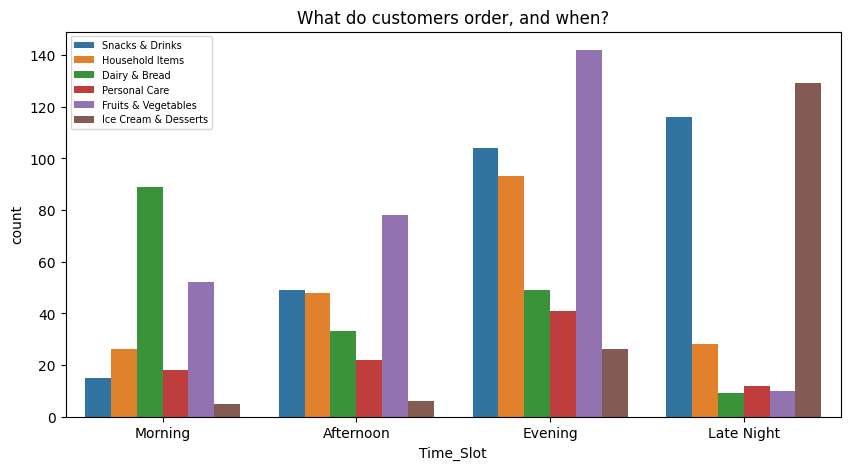

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define standard orders so charts always show groups in a sensible order
slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Time_Slot", order=slot_order, hue="Category")
plt.title("What do customers order, and when?")
plt.legend(fontsize=7)
plt.show()

#Which time slot has the slowest and least predictability


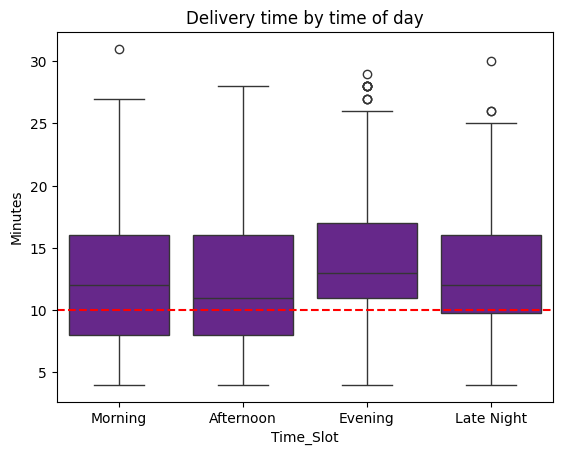

In [ ]:
sns.boxplot(data=df, x="Time_Slot", y="Delivery_Time_Min", order=slot_order, color="#6A189A")
plt.axhline(10, color="red", linestyle="--")
plt.title("Delivery time by time of day")
plt.ylabel("Minutes")
plt.show()

Do past members spent differently from new members

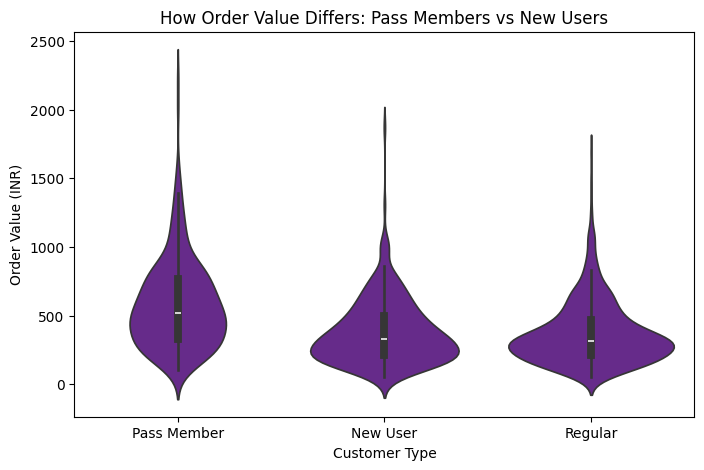

In [ ]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="Customer_Type", y="Order_Value", color="#6A1B9A")
plt.title("How Order Value Differs: Pass Members vs New Users")
plt.xlabel("Customer Type")
plt.ylabel("Order Value (INR)")
plt.show()

#Are low rating caused by many orders or few - Striplot by seaborn

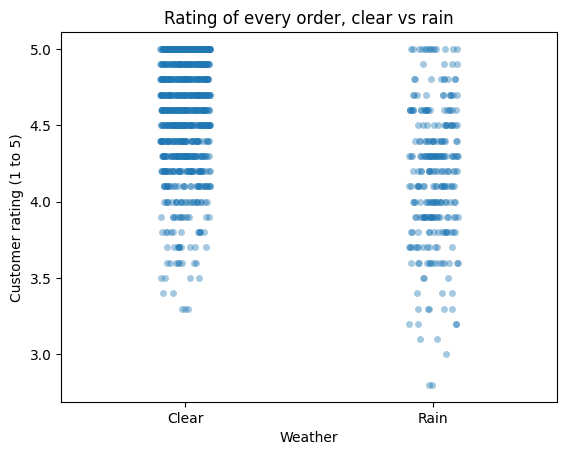

In [ ]:
sns.stripplot(data=df, x="Weather", y="Customer_Rating", jitter=True, alpha=0.4)
plt.title("Rating of every order, clear vs rain")
plt.ylabel("Customer rating (1 to 5)")
plt.show()

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_excel("/content/Starbucks_Stores_Data.xlsx", sheet_name="Stores")

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 300 | Columns: 25


,Store_ID,City,City_Tier,Location_Type,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,...,Taste_Score,Service_Score,Cleanliness_Score,Ambience_Score,Staff_Friendliness_Score,Avg_Wait_Time_Min,Monthly_Footfall_K,Avg_Bill_INR,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh
0,ST-001,Hyderabad,Metro,Airport or Transit,790,37,9,129,136,46,...,5.6,4.9,5.7,6.2,6.1,5.0,14.5,281,35.3,79.2
1,ST-002,Nagpur,Tier 3,High Street,1400,50,14,95,34,28,...,6.8,7.1,7.1,6.3,7.0,6.2,14.7,280,40.4,79.9
2,ST-003,Kolkata,Metro,High Street,1120,44,10,76,78,53,...,9.0,8.8,9.4,8.8,8.5,3.5,16.1,362,46.1,84.1
3,ST-004,Delhi NCR,Metro,High Street,1830,67,19,53,57,23,...,6.8,6.8,7.2,7.2,7.2,4.8,15.9,291,39.5,85.9
4,ST-005,Chennai,Metro,Mall,1300,54,13,198,103,94,...,6.7,5.6,6.1,7.1,6.3,5.1,19.1,296,37.5,123.0


In [ ]:
df.describe().round(1)

,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,Promo_Offers_Count,App_Orders_Share_Pct,Loyalty_Members_K,App_Rating,...,Taste_Score,Service_Score,Cleanliness_Score,Ambience_Score,Staff_Friendliness_Score,Avg_Wait_Time_Min,Monthly_Footfall_K,Avg_Bill_INR,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh
count,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,...,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0
mean,1192.8,45.3,11.7,128.4,86.2,54.0,6.2,25.0,21.6,4.2,...,7.3,7.0,7.5,7.3,7.4,6.1,15.9,310.5,39.4,88.8
std,343.4,13.5,3.1,46.2,33.8,22.4,2.4,7.2,7.4,0.3,...,0.8,1.0,0.8,0.8,0.9,1.5,4.2,25.2,6.8,20.3
min,500.0,14.0,5.0,30.0,15.0,8.0,1.0,6.0,4.0,3.4,...,4.9,4.2,5.7,5.0,4.3,2.5,5.0,235.0,15.0,45.5
25%,950.0,37.0,9.0,95.0,62.8,39.8,4.0,20.3,16.6,4.1,...,6.8,6.3,7.0,6.8,6.8,5.0,12.9,294.0,35.2,75.6
50%,1210.0,45.0,12.0,127.0,85.0,54.0,6.0,25.8,22.0,4.2,...,7.3,7.0,7.4,7.3,7.3,6.0,15.9,310.0,40.0,86.1
75%,1440.0,54.0,14.0,158.0,109.0,69.0,8.0,30.0,26.5,4.4,...,7.8,7.7,8.0,7.7,8.0,7.2,18.6,327.0,44.0,98.1
max,2000.0,80.0,19.0,260.0,179.0,120.0,13.0,48.0,40.1,4.9,...,9.7,10.0,9.7,9.2,9.7,11.1,26.6,382.0,58.1,170.8


#Which business variable do we want to relate to and what type is it?


In [ ]:
numbers = df.select_dtypes(include="number").columns.tolist()
categories = df.select_dtypes(exclude="number").columns.tolist()

print("Number Variables:", len(numbers))
print("Category Variables:", len(categories))
print("Category Variables:", categories)

Number Variables: 21
Category Variables: 4
Category Variables: ['Store_ID', 'City', 'City_Tier', 'Location_Type']


In [ ]:
#The nine key variables we will use in Part C
key_cols = ["Social_Media_Spend_K", "App_Orders_Share_Pct",
    "Seats",
    "Staff_Count",
    "Avg_Wait_Time_Min",
    "Service_Score",
    "Repeat_Customer_Pct",
    "Monthly_Footfall_K",
    "Monthly_Sales_INR_Lakh"
]

#Do stores with a high share of App orders sell more?


In [ ]:
import matplotlib.pyplot as plt


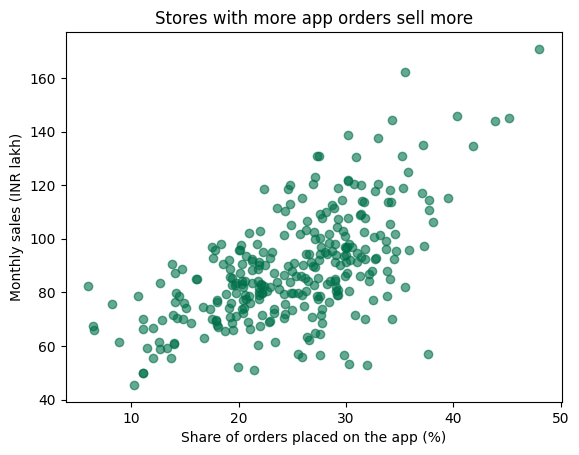

In [ ]:
plt.scatter(
    df["App_Orders_Share_Pct"],
    df["Monthly_Sales_INR_Lakh"],
    alpha=0.6,
    color="#00704A"
)

plt.xlabel("Share of orders placed on the app (%)")
plt.ylabel("Monthly sales (INR lakh)")
plt.title("Stores with more app orders sell more")
plt.show()

#NEGATIVE RELATIONSHIP
# Do longer waits mean fewer repeat customers ?

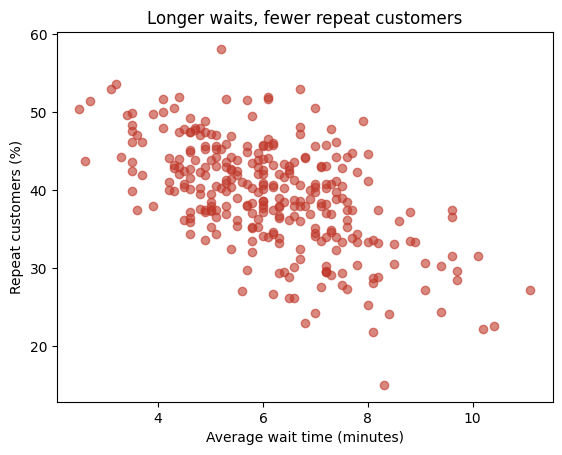

In [ ]:
plt.scatter(
    df["Avg_Wait_Time_Min"],
    df["Repeat_Customer_Pct"],
    alpha=0.6,
    color="#C0392B"
)

plt.title("Longer waits, fewer repeat customers")
plt.xlabel("Average wait time (minutes)")
plt.ylabel("Repeat customers (%)")
plt.show()

#NEUTRAL RELATIONSHIP/ NO RELATIONSHIP AMONG VARIABLES

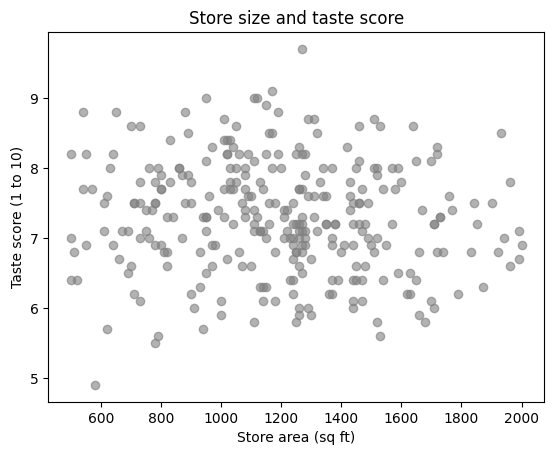

In [ ]:
plt.scatter(
    df["Store_Area_SqFt"],
    df["Taste_Score"],
    alpha=0.6,
    color="grey"
)

plt.title("Store size and taste score")
plt.xlabel("Store area (sq ft)")
plt.ylabel("Taste score (1 to 10)")
plt.show()

#CORRELATION COEFFICIENT
HOW LONG IS THE RELATIONSHIP AMONG VARIABLES AND IN WHICH DIRECTION

In [ ]:
r1 = df["App_Orders_Share_Pct"].corr(df["Monthly_Sales_INR_Lakh"])
r2 = df["Avg_Wait_Time_Min"].corr(df["Repeat_Customer_Pct"])
r3 = df["Store_Area_SqFt"].corr(df["Taste_Score"])

print("App share and sales    :", round(r1, 2))
print("Wait time and repeat   :", round(r2, 2))
print("Store area and taste   :", round(r3, 2))

App share and sales    : 0.61
Wait time and repeat   : -0.58
Store area and taste   : -0.09


#Overall correlation matrix - How are all the key variables ralated to each other ?

In [ ]:
corr = df[key_cols].corr().round(2)

corr

,Social_Media_Spend_K,App_Orders_Share_Pct,Seats,Staff_Count,Avg_Wait_Time_Min,Service_Score,Repeat_Customer_Pct,Monthly_Footfall_K,Monthly_Sales_INR_Lakh
Social_Media_Spend_K,1.00,0.40,-0.00,0.03,-0.01,-0.06,-0.02,0.32,0.67
App_Orders_Share_Pct,0.40,1.00,-0.03,-0.02,0.03,-0.03,-0.03,0.44,0.61
Seats,-0.00,-0.03,1.00,0.75,0.13,-0.09,-0.07,0.53,0.37
Staff_Count,0.03,-0.02,0.75,1.00,0.07,-0.01,-0.04,0.54,0.30
Avg_Wait_Time_Min,-0.01,0.03,0.13,0.07,1.00,-0.26,-0.58,-0.05,0.04
Service_Score,-0.06,-0.03,-0.09,-0.01,-0.26,1.00,0.75,0.25,-0.01
Repeat_Customer_Pct,-0.02,-0.03,-0.07,-0.04,-0.58,0.75,1.00,0.17,-0.01
Monthly_Footfall_K,0.32,0.44,0.53,0.54,-0.05,0.25,0.17,1.00,0.59
Monthly_Sales_INR_Lakh,0.67,0.61,0.37,0.30,0.04,-0.01,-0.01,0.59,1.00


#WHERE ARE THE STRONG AND WEAK RELATIONSHIP?

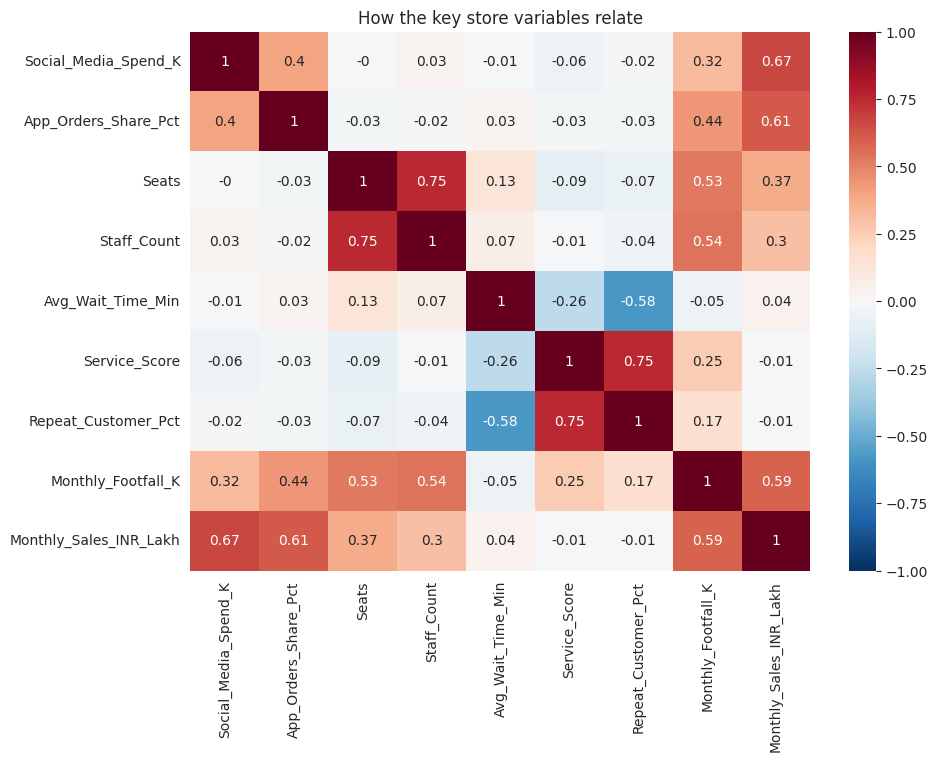

In [ ]:
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)

plt.title("How the key store variables relate")
plt.show()

#STATISTICAL MODELLING- LINEAR REGRESSION AND MULTIPLE REGRESSION

In [ ]:
import statsmodels.formula.api as smf

m_social = smf.ols(
    "Monthly_Sales_INR_Lakh ~ Social_Media_Spend_K",
    data=df
).fit()

print(m_social.summary().tables[1])
print("R-squared:", round(m_social.rsquared, 2))

                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               50.9018      2.574     19.775      0.000      45.836      55.967
Social_Media_Spend_K     0.2950      0.019     15.631      0.000       0.258       0.332
R-squared: 0.45


#Interpretation of Linear Regression
#A unit increase in social media spending is associated with .25 lakhs increase in monthly sales since the coefficient is positive therefore it is increasing the sales since the coefficient is positive therefore it is increasing the sales.
-R square Social media spending explains 45% of the variation in monthly sales
-p value/ significance level social media spending a statistically significant positive relationship with monthly sales.

Negative Relationship among variables in linear Regression

In [ ]:
m_wait = smf.ols(
    "Repeat_Customer_Pct ~ Avg_Wait_Time_Min",
    data=df
).fit()

print(m_wait.summary().tables[1])
print("R-squared:", round(m_wait.rsquared, 2))

                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            55.2749      1.339     41.276      0.000      52.639      57.910
Avg_Wait_Time_Min    -2.5949      0.212    -12.224      0.000      -3.013      -2.177
R-squared: 0.33


#What are the other attributes that can effect monthly sales?

In [ ]:
m_multi = smf.ols(
    "Monthly_Sales_INR_Lakh ~ Social_Media_Spend_K + App_Orders_Share_Pct",
    data=df
).fit()

print(m_multi.summary().tables[1])
print("R-squared:", round(m_multi.rsquared, 2))

                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               31.1703      2.967     10.504      0.000      25.330      37.010
Social_Media_Spend_K     0.2241      0.018     12.601      0.000       0.189       0.259
App_Orders_Share_Pct     1.1515      0.114     10.059      0.000       0.926       1.377
R-squared: 0.59


In [ ]:
Continuous of Linear Regression

SyntaxError: invalid syntax (2003951802.py, line 1)

Linear Regression with Controlled Variable
#Does staff count still matter once store size is held fixed?

In [ ]:
import statsmodels.formula.api as smf

m_staff_alone = smf.ols(
    "Monthly_Sales_INR_Lakh ~ Staff_Count",
    data=df
).fit()

m_staff_ctrl = smf.ols(
    "Monthly_Sales_INR_Lakh ~ Staff_Count + Seats",
    data=df
).fit()

print(m_staff_alone.summary().tables[1])
print("R-squared:", round(m_staff_alone.rsquared, 2))

print(m_staff_ctrl.summary().tables[1])
print("R-squared:", round(m_staff_ctrl.rsquared, 2))

print(
    "Staff effect alone:",
    round(m_staff_alone.params["Staff_Count"], 2),
    "| p-value:",
    round(m_staff_alone.pvalues["Staff_Count"], 3)
)

print(
    "Staff effect with Seats:",
    round(m_staff_ctrl.params["Staff_Count"], 2),
    "| p-value:",
    round(m_staff_ctrl.pvalues["Staff_Count"], 3)
)

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      66.0724      4.371     15.115      0.000      57.470      74.675
Staff_Count     1.9441      0.362      5.371      0.000       1.232       2.656
R-squared: 0.09
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      62.4999      4.354     14.356      0.000      53.932      71.068
Staff_Count     0.3474      0.530      0.656      0.512      -0.695       1.390
Seats           0.4907      0.121      4.043      0.000       0.252       0.730
R-squared: 0.14
Staff effect alone: 1.94 | p-value: 0.0
Staff effect with Seats: 0.35 | p-value: 0.512


#Interpretation of Linear Regression

#After Introducing another variable customer seats as an additional independent variable, the coefficient reduced from 1.94 to 0.34 and p value become insignificant, this means the staff count is no longer significant after controlling staff count with customer sitting suggesting that the restaurant with greater seating capacity tends to generate higher monthly sales.

#Linear Regression with moderation effect/ Interaction Effect

In [ ]:
# Centre the numbers: subtract the average

df["Social_c"] = df["Social_Media_Spend_K"] - df["Social_Media_Spend_K"].mean()

df["App_c"] = df["App_Orders_Share_Pct"] - df["App_Orders_Share_Pct"].mean()

df["Wait_c"] = df["Avg_Wait_Time_Min"] - df["Avg_Wait_Time_Min"].mean()

df["Service_c"] = df["Service_Score"] - df["Service_Score"].mean()

# A yes or no flag: 1 = Metro store, 0 = other

df["Is_Metro"] = (df["City_Tier"] == "Metro").astype(int)

#Does the effect social media spending depend on how digital the store is?

In [ ]:
m_digital = smf.ols(
    "Monthly_Sales_INR_Lakh ~ Social_c * App_c",
    data=df
).fit()

print(m_digital.summary().tables[1])
print("R-squared:", round(m_digital.rsquared, 2))

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         86.0459      0.685    125.677      0.000      84.698      87.393
Social_c           0.2270      0.015     15.076      0.000       0.197       0.257
App_c              1.1605      0.097     11.975      0.000       0.970       1.351
Social_c:App_c     0.0208      0.002     10.881      0.000       0.017       0.025
R-squared: 0.71


#Interpretation
#The Regression results shows that social media spending and app based ordering have a positive and significant impact on monthly sales. In addition,the interaction effect of social media spending and app based ordering have a coefficient of 0.0208, which is positive and statistically significant on monthly sales. This suggest that the social media spending and monthly sales becomes stronger in presence of app based order.

#Data visualisation for high and low app based share

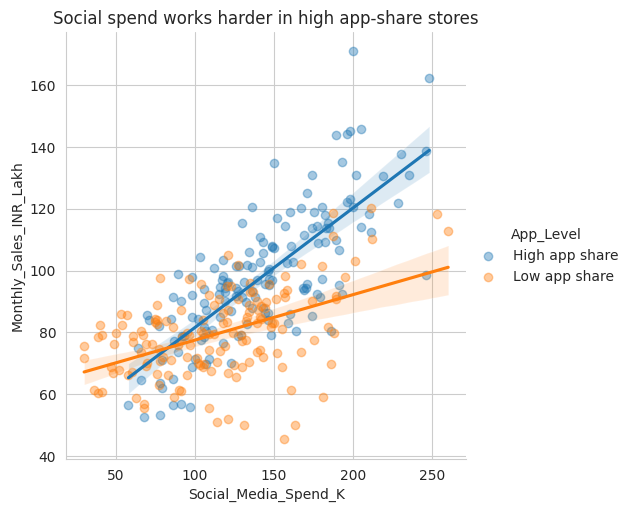

In [ ]:
df["App_Level"] = np.where(
    df["App_Orders_Share_Pct"] > df["App_Orders_Share_Pct"].median(),
    "High app share",
    "Low app share"
)

g = sns.lmplot(
    data=df,
    x="Social_Media_Spend_K",
    y="Monthly_Sales_INR_Lakh",
    hue="App_Level",
    height=5,
    scatter_kws={"alpha": 0.4}
)

g.set(title="Social spend works harder in high app-share stores")

plt.show()

#Principle Component Analysis / Logical Index

In [ ]:
#Step 1: Grouping the variable

groups = {
    "Customer Experience": [
        "Taste_Score",
        "Service_Score",
        "Cleanliness_Score",
        "Ambience_Score",
        "Staff_Friendliness_Score"
    ],
    "Digital Engagement": [
        "App_Orders_Share_Pct",
        "Loyalty_Members_K",
        "App_Rating",
        "Social_Followers_K"
    ],
    "Marketing Intensity": [
        "Social_Media_Spend_K",
        "Outdoor_Ad_Spend_K",
        "Influencer_Spend_K",
        "Promo_Offers_Count"
    ],
    "Store Capacity": [
        "Store_Area_SqFt",
        "Seats",
        "Staff_Count"
    ]
}

for name, cols in groups.items():
    c = df[cols].corr().values

    average = (c.sum() - len(cols)) / (
        len(cols) * (len(cols) - 1)
    )  # average correlation inside the group

    print(
        f"{name}: {len(cols)} variables, "
        f"average correlation {average:.2f}"
    )


Customer Experience: 5 variables, average correlation 0.79
Digital Engagement: 4 variables, average correlation 0.77
Marketing Intensity: 4 variables, average correlation 0.74
Store Capacity: 3 variables, average correlation 0.77


In [ ]:
#Step 2: Can 5 survey scores become 1 experience score?

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

cols = groups["Customer Experience"]

# Step A: Put every variable on the same scale
scaled = StandardScaler().fit_transform(df[cols])

# Step B: Run PCA
pca = PCA()
scores = pca.fit_transform(scaled)

# Step C: How much does each component explain?
names = [f"PC{i+1}" for i in range(len(cols))]

print(
    pd.Series(
        pca.explained_variance_ratio_,
        index=names
    ).round(2)
)


PC1    0.83
PC2    0.06
PC3    0.04
PC4    0.03
PC5    0.03
dtype: float64


In [ ]:
#Step D: the loadings show how much each variable counts in PC1
sign = 1 if pca.components_[0].sum() > 0 else -1
# make sure a higher score means a better experience
print(pd.Series(pca.components_[0] * sign, index=cols).round(2))

Taste_Score                 0.45
Service_Score               0.46
Cleanliness_Score           0.45
Ambience_Score              0.42
Staff_Friendliness_Score    0.45
dtype: float64


In [ ]:
#Step E: turn PC1 into an index from 0 to 100
raw_index = scores[:, 0] * sign

df["Experience_Index"] = (
    (raw_index - raw_index.min()) /
    (raw_index.max() - raw_index.min()) * 100
)

df[["Store_ID", "City", "Experience_Index"]].sort_values(
    "Experience_Index",
    ascending=False
).head(5).round(1)

,Store_ID,City,Experience_Index
228,ST-229,Hyderabad,100.0
278,ST-279,Chandigarh,97.0
22,ST-023,Kochi,95.8
15,ST-016,Hyderabad,95.3
2,ST-003,Kolkata,95.1
